In [12]:
%pip install -q requests pydantic python-dotenv pandas matplotlib numpy httpx langgraph langchain langchain-openai smolagents


[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [28]:
import hashlib
import json
import os
import re
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from typing import TypedDict
from dataclasses import dataclass, field


os.environ.setdefault("LANGCHAIN_OPENAI_TCP_KEEPALIVE", "0")

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from pymilvus import MilvusClient

from langchain.agents import create_agent
from langchain.agents.middleware import (
    HumanInTheLoopMiddleware,
    ModelCallLimitMiddleware,
    wrap_model_call,
)
from langchain_core.messages import HumanMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command


In [72]:
warnings.filterwarnings("ignore")
load_dotenv()

KEY = os.getenv("OPENROUTER_API_KEY")
assert KEY, "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

BASE_URL = "https://openrouter.ai/api/v1"
CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}", "X-Title": "agents-course-seminar02"}
EMBED_MODEL, DIM = "openai/text-embedding-3-small", 512
CHEAP, MID, STRONG = "openai/gpt-4o-mini", "anthropic/claude-haiku-4.5", "anthropic/claude-sonnet-4.6"
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data"
SAMPLE, STRONG_SAMPLE = 40, 40
Path("img").mkdir(exist_ok=True)
output_dir = ROOT / "results"
output_dir.mkdir(exist_ok=True)

def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

def pmap(fn, items, workers=6):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(fn, items))

In [36]:
client = MilvusClient(
    uri=os.getenv("MILVUS_URI", "http://localhost:19530"),
    token=os.getenv("MILVUS_TOKEN", ""),
)

if os.getenv("MILVUS_DB"):
    client.use_database(os.environ["MILVUS_DB"])

In [ ]:
if not client.has_collection("lines"):
    chunks = []
    for page in load_jsonl("corpus_2026.jsonl"):
        for line in page["text"].splitlines():
            line = " ".join(line.split())
            if len(line) > 40:
                chunks.append({
                    "page": page["page"], "section": "",
                    "url": page["url"], "text": line,
                })

    with np.load(ROOT / "src" / "emb_cache.npz") as cache:
        vectors_by_key = dict(zip(cache["keys"], cache["vectors"]))

    vectors = np.stack([
        vectors_by_key[hashlib.sha1(
            f"{c['page']}: {c['text']}".encode("utf-8")
        ).hexdigest()]
        for c in chunks
    ]).astype(np.float32)
    vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)

    client.create_collection("lines", dimension=DIM, metric_type="COSINE")
    client.insert("lines", [
        {"id": i, "vector": v.tolist(), **c}
        for i, (c, v) in enumerate(zip(chunks, vectors))
    ])
    client.flush("lines")

print(client.get_collection_stats("lines"))

In [31]:
EMB = {}

def load_cache():
    for path in [DATA / "embeddings_512.npz", Path("emb_cache.npz")]:
        if path.exists():
            z = np.load(path)
            EMB.update({str(k): v.astype(np.float32) for k, v in zip(z["keys"], z["vectors"])})
    return len(EMB)

def save_cache():
    np.savez_compressed("emb_cache.npz", keys=np.array(list(EMB)), vectors=np.stack(list(EMB.values())).astype(np.float16))

def embed_batch(texts):
    response = HTTP.post(
        EMBED_URL,
        headers=HEADERS,
        json={
            "model": EMBED_MODEL,
            "input": texts,
            "dimensions": DIM,
        },
    )
    response.raise_for_status()

    rows = sorted(response.json()["data"], key=lambda row: row["index"])
    return [row["embedding"] for row in rows]

def key_of(text):
    return hashlib.sha1(text.encode("utf-8")).hexdigest()

load_cache()

963

In [32]:
def embed_cached(texts):
    missing = list(dict.fromkeys(t for t in texts if key_of(t) not in EMB))
    for i in range(0, len(missing), 64):
        batch = missing[i:i + 64]
        for text, vector in zip(batch, embed_batch(batch)):
            EMB[key_of(text)] = np.array(vector, dtype=np.float32)

    vectors = np.stack([EMB[key_of(t)] for t in texts])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)

In [33]:
def search_milvus(name, query, k=5, flt=""):
    vector = embed_cached([query])[0].tolist()
    hits = client.search(name, data = [vector], limit=k, filter=flt, output_fields=["page", "section", "url", "text"])[0]

    return [{**h['entity'], "id" : h['id'], "score": round(h['distance'], 4)} for h in hits]


In [38]:
def knowledge_base(query: str, page: str = "") -> str:
    hits = search_milvus(
        "lines", query, 5,
        f'page == "{page}"' if page else "",
    )

    if not hits:
        return "NOTHING_FOUND"

    return "\n".join(
        f"[{i + 1}] ({h['page']}) / {h['section']} {h['text']}"
        for i, h in enumerate(hits)
    )

In [34]:
CALLS, FIRST, TAG = [], {}, {"now": "без метки"}

In [35]:
def on_response(response):
    response.read()
    request = json.loads(response.request.content or b"{}")
    usage = response.json().get("usage") or {}
    FIRST.setdefault(TAG["now"], request)
    CALLS.append({
        "tag":TAG["now"],
        "model": request.get("model", "?").split("/")[-1],
        "messages": len(request.get("messages", [])),
        "tools": len(request.get("tools", [])),
        "prompt": usage.get("prompt_tokens", 0),
        "completion": usage.get("completion_tokens", 0),
        "cost": usage.get("cost") or 0

    })

In [51]:
HTTP = httpx.Client(event_hooks={"response": [on_response]}, timeout=180)
HEADERS = {"Authorization": f"Bearer {KEY}", "X-Title": "agents-course-seminar03"}

def chat(messages, model=CHEAP, tools=None, temperature=0.0):
    body = {"model": model, "messages": messages, "temperature": temperature}
    if tools:
        body["tools"] = tools
    for attempt in range(5):
        r = HTTP.post(f"{BASE_URL}/chat/completions", json=body, headers=HEADERS)
        if r.status_code == 200:
            return r.json()["choices"][0]["message"]
        time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"HTTP {r.status_code}: {r.text[:200]}")

TAG["now"] = "проверка счётчика"
chat([{"role": "user", "content": "Say OK"}])
pd.DataFrame(CALLS)

,tag,model,messages,tools,prompt,completion,cost
0,проверка агента,text-embedding-3-small,0,0,6,0,1.200000e-07
1,проверка LangGraph,gpt-4o-mini,2,1,169,19,3.675000e-05
2,проверка LangGraph,text-embedding-3-small,0,0,5,0,1.000000e-07
3,проверка LangGraph,gpt-4o-mini,4,1,387,23,7.185000e-05
4,"LangGraph, mini",gpt-4o-mini,2,1,169,19,3.675000e-05
...,...,...,...,...,...,...,...
74,"LangGraph, mini",gpt-4o-mini,5,1,1073,63,1.987500e-04
75,"LangGraph, mini",text-embedding-3-small,0,0,7,0,1.400000e-07
76,"LangGraph, mini",gpt-4o-mini,6,1,850,44,1.539000e-04
77,"LangGraph, mini",gpt-4o-mini,4,1,371,24,7.005000e-05


In [40]:
TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}

def run_tool(call):
    name = call["function"]["name"]
    try:
        spec = TOOLS[name]
        result = spec["fn"](**spec["args"].model_validate_json(call["function"]["arguments"]).model_dump())
    except Exception as e:
        result = f"ошибка инструмента {name}: {e}"
    return {"role": "tool", "tool_call_id": call["id"], "content": str(result)[:3000]}

AGENT_SYSTEM = ("You answer questions about events of 2026. Never answer from memory: look facts up with the tools, do not repeat the same call. "
                "When done, write the last line as FINAL: <short answer>, or NOT_FOUND if the knowledge base has no answer.")

def agent(question, model=CHEAP, max_steps=6):
    messages = [
        {"role": "system", "content": AGENT_SYSTEM},
        {"role": "user", "content": question},
    ]
    seen = set()
    schemas = [t["schema"] for t in TOOLS.values()]
    for step in range(max_steps):
        msg = chat(messages, model, tools=schemas)
        messages.append(msg)
        calls = msg.get("tool_calls") or []
        keys = {(c["function"]["name"], c["function"]["arguments"]) for c in calls}
        if not calls or keys & seen or step == max_steps - 1:
            break
        seen |= keys
        messages += [run_tool(c) for c in calls]
    if calls:
        messages += [{"role": "tool", "tool_call_id": c["id"], "content": "call rejected: answer from what you already have"} for c in calls]
        msg = chat(messages, model)
    searches = sum(m.get("role") == "tool" for m in messages if isinstance(m, dict))
    return {"answer": msg.get("content") or ""}

class KBArgs(BaseModel):
    query: str = Field(description="short search query in English: names, dates, key terms of the event")
    page: str = Field(default="", description="optional exact page title to search within, for example '2026 in Japan'; empty means all pages")

def bare_agent(question, model=CHEAP):
    return agent(question, model)["answer"]

register(
    knowledge_base,
    KBArgs,
    "Searches the local knowledge base of 2026 events and returns "
    "the five closest facts with their page and section",
)

In [42]:
tasks = load_jsonl("fresh_2026.jsonl")

with np.load(ROOT / "src" / "emb_cache.npz") as cache:
    EMB = {
        str(key): vector.astype(np.float32)
        for key, vector in zip(cache["keys"], cache["vectors"])
    }

register(
    knowledge_base,
    KBArgs,
    "Searches the local knowledge base of 2026 events and returns "
    "the five closest facts with their page and section",
)

def bare_agent(question, model=CHEAP):
    return agent(question, model)["answer"]

print("Вопросов:", len(tasks))
print("Инструменты:", list(TOOLS))

Вопросов: 50
Инструменты: ['knowledge_base']


In [43]:
TAG["now"] = "проверка агента"

print("Вопрос:", tasks[0]["question"])
print("Ответ:", bare_agent(tasks[0]["question"]))
print("Эталон:", tasks[0]["answer"])

Вопрос: Who won the 2026 Australian Grand Prix?
Ответ: The winner of the 2026 Australian Grand Prix was George Russell from the Mercedes team. FINAL: George Russell
Эталон: George Russell


In [52]:
LC_TOOLS = [
    tool(
        knowledge_base,
        args_schema=KBArgs,
        description=TOOLS["knowledge_base"]["schema"]["function"]["description"],
    )
]

LG_MIDDLEWARE = [
    ModelCallLimitMiddleware(run_limit=7, exit_behavior="end")
]

def lc_model(model=CHEAP, temperature=0.0):
    return ChatOpenAI(
        model=model,
        base_url=BASE_URL,
        api_key=KEY,
        http_client=HTTP,
        temperature=temperature,
    )

In [53]:
def run_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    agent = create_agent(lc_model(model, temperature), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM + extra, middleware=LG_MIDDLEWARE)
    out = agent.invoke(
        {"messages": [{"role": "user", "content": question}]},
        {"recursion_limit": 30}
    )
    return out["messages"]


In [54]:
def ask_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    return run_langgraph(
        question, model, temperature, extra
    )[-1].content

TAG["now"] = "проверка LangGraph"

print("Вопрос:", tasks[0]["question"])
print("Ответ:", ask_langgraph(tasks[0]["question"]))
print("Эталон:", tasks[0]["answer"])

Вопрос: Who won the 2026 Australian Grand Prix?
Ответ: The winner of the 2026 Australian Grand Prix was George Russell from the Mercedes team. FINAL: George Russell
Эталон: George Russell


In [57]:
def color_of(tag):
    return COLORS["amber"] if "Sonnet" in tag else COLORS["violet"]

def money_chart(tags, path, title):
    table = report(tags)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.set_xscale("log")
    for _, r in table.iterrows():
        ax.scatter(r["центов на вопрос"], r["доля"] * 100, s=110, color=color_of(r["конфигурация"]), zorder=3)
    ax.margins(x=0.15, y=0.12)
    fig.canvas.draw()
    placed = []
    for _, r in table.sort_values("центов на вопрос").iterrows():
        for dx, dy in [(8, 4), (8, -12), (-8, 4), (-8, -12), (8, 16), (8, -24)]:
            label = ax.annotate(r["конфигурация"], (r["центов на вопрос"], r["доля"] * 100), xytext=(dx, dy), textcoords="offset points",
                                fontsize=8.5, ha="left" if dx > 0 else "right", color=color_of(r["конфигурация"]))
            box = label.get_window_extent()
            if not any(box.overlaps(b) for b in placed) or dy == -24:
                break
            label.remove()
        placed.append(box)
    ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %")
    ax.set_title(title); ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return table

In [58]:

class QA(TypedDict):
    question: str
    answer: str
    evidence: str
    feedback: str
    rounds: int
    checks: int

class Verdict(BaseModel):
    supported: bool = Field(description="true only if the evidence explicitly supports the answer")
    issue: str = Field(description="what is wrong or missing, empty if supported")

CRITIC_SYSTEM = (
    "Check the answer using only the evidence retrieved "
    "from the local knowledge base. "
    "The answer is supported only if the evidence supports "
    "all its factual claims. "
    "If evidence is missing or contradicts the answer, "
    "mark it unsupported and explain what needs fixing."
)

def answer_node(state):
    note = ""
    if state["feedback"]:
        note = f"\n\nA reviewer rejected your previous answer '{state['answer']}': {state['feedback']} Search again and correct it."
    messages = run_langgraph(state["question"] + note)
    found = "\n".join(str(m.content)[:800] for m in messages if m.type == "tool")
    return {"answer": messages[-1].content, "evidence": found[-4000:], "rounds": state["rounds"] + 1}

In [59]:
def critic_node(state):
    judge = lc_model(CHEAP).with_structured_output(Verdict)
    verdict = judge.invoke([
        ("system", CRITIC_SYSTEM),
        ("user", f"Question: {state['question']}\nAnswer: {state['answer']}\n"
                 f"Evidence the agent found:\n{state['evidence'] or 'nothing'}")
    ])
    return {"feedback": "" if verdict.supported else verdict.issue, "checks": state["checks"] + 1}


In [60]:
def route(state):
    if state["feedback"] and state["rounds"] < 3:
        return "answer"
    return END

In [81]:
NUMBERS = {w: str(n) for n, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve".split())}

def norm(text):
    return " ".join(NUMBERS.get(w, w) for w in re.sub(r"\b(a|an|the)\b|[^\w\s]", " ", str(text).lower()).split())

def is_correct(task, answer):
    return set(norm(task["answer"]).split()) <= set(norm(answer).split())

RESULTS = {}

def run_config(tag, fn, sample=None, workers=6):
    sample = sample or tasks
    TAG["now"] = tag
    def one(task):
        try:
            return fn(task["question"])
        except Exception as e:
            return f"ошибка: {type(e).__name__}"
    answers = pmap(one, sample, workers)
    RESULTS[tag] = [{"id": t["id"], "answer": a, "ok": is_correct(t, a)} for t, a in zip(sample, answers)]
    return report([tag])

def report(tags=None):
    rows = []
    for tag in tags or RESULTS:
        res = RESULTS[tag]
        calls = [c for c in CALLS if c["tag"] == tag]
        models = [c for c in calls if c["model"] != EMBED_MODEL.split("/")[-1]]
        n, ok = len(res), sum(r["ok"] for r in res)
        cost = sum(c["cost"] for c in calls) * 100
        rows.append({
            "конфигурация": tag,
            "верно": f"{ok}/{n}",
            "доля": round(ok / n, 3),
            "вызовов на вопрос": round(len(models) / n, 2),
            "токенов на вопрос": round(sum(c["prompt"] + c["completion"] for c in models) / n),
            "центов на вопрос": round(cost / n, 4),
            "центов за верный": round(cost / ok, 4) if ok else None,
        })
    return pd.DataFrame(rows)

def wrong(tag, n=10):
    return pd.DataFrame([{"эталон": t["answer"], "ответ": str(r["answer"])[:110]}
                         for t, r in zip(tasks, RESULTS[tag]) if not r["ok"]][:n])

In [82]:
graph = StateGraph(QA)
graph.add_node("answer", answer_node)
graph.add_node("critic", critic_node)
graph.add_edge(START, "answer")
graph.add_edge("answer", "critic")
graph.add_conditional_edges("critic", route, ["answer", END])
checked = graph.compile()
print(checked.get_graph().draw_mermaid())

def ask_checked(question):
    return checked.invoke({"question": question, "answer": "", "evidence": "", "feedback": "", "rounds": 0, "checks": 0})["answer"]

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	answer(answer)
	critic(critic)
	__end__([<p>__end__</p>]):::last
	__start__ --> answer;
	answer --> critic;
	critic -.-> __end__;
	critic -.-> answer;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [62]:
TAG["now"] = "проверка критика"

result = checked.invoke({
    "question": tasks[0]["question"],
    "answer": "",
    "evidence": "",
    "feedback": "",
    "rounds": 0,
    "checks": 0,
})

print("Вопрос:", tasks[0]["question"])
print("Ответ:", result["answer"])
print("Эталон:", tasks[0]["answer"])
print("Попыток ответа:", result["rounds"])
print("Проверок критика:", result["checks"])
print("Замечание:", result["feedback"] or "нет")

Вопрос: Who won the 2026 Australian Grand Prix?
Ответ: The winner of the 2026 Australian Grand Prix was George Russell from the Mercedes team. FINAL: George Russell
Эталон: George Russell
Попыток ответа: 1
Проверок критика: 1
Замечание: нет


In [89]:
tags = ["LangGraph, mini", "LangGraph + критик, mini"]
CALLS[:] = [c for c in CALLS if c["tag"] not in tags]

for tag in tags:
    FIRST.pop(tag, None)

initial_cache = EMB.copy()
run_config(tags[0], ask_langgraph, sample=tasks, workers=2)
EMB = initial_cache.copy()
run_config(tags[1], ask_checked, sample=tasks, workers=2)

base, crit = RESULTS[tags[0]], RESULTS[tags[1]]
fixed = sum(not b["ok"] and c["ok"] for b, c in zip(base, crit))
broken = sum(b["ok"] and not c["ok"] for b, c in zip(base, crit))

print("Исправил:", fixed, "| Испортил:", broken)
report(tags)

Исправил: 1 | Испортил: 0


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",43/50,0.86,2.98,1731,0.0281,0.0327
1,"LangGraph + критик, mini",44/50,0.88,5.48,3779,0.0573,0.0651


In [63]:
PLAN_SYSTEM = (
    "Write a short plan of 2-4 steps to answer the question "
    "using knowledge_base(query, page=''). "
    "The tool searches a local knowledge base about events of 2026. "
    "Suggest search queries and what facts to look for. "
    "Do not invent facts or answer the question. Return only the plan."
)

In [64]:
def plan_then_act(question):
    plan = lc_model(CHEAP).invoke([("system", PLAN_SYSTEM), ("user", question)]).content
    return ask_langgraph(question, CHEAP, extra="\nFollow this plan:\n" + plan)


In [65]:
TAG["now"] = "проверка планировщика"

print("Вопрос:", tasks[0]["question"])
print("Ответ:", plan_then_act(tasks[0]["question"]))
print("Эталон:", tasks[0]["answer"])

Вопрос: Who won the 2026 Australian Grand Prix?
Ответ: The winner of the 2026 Australian Grand Prix was George Russell, driving for Mercedes. He completed the race in a time of 1:23:06.801. 

FINAL: George Russell
Эталон: George Russell


In [68]:
TAG["now"] = "бюджет"
capped = create_agent(lc_model(CHEAP), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM,
                      middleware=[ModelCallLimitMiddleware(run_limit=1, exit_behavior="end")])

before = len(CALLS)

out = capped.invoke({"messages": [{"role": "user", "content": "Compare the months of the 2026 Winter Olympics and the 2026 FIFA World Cup, then list three events of each."}]})
print(out["messages"][-1].content)
print("Вызовов модели:", sum(c["model"] == CHEAP.split("/")[-1] for c in CALLS[before:]),)

Model call limits exceeded: run limit (1/1)
Вызовов модели: 1


In [76]:
def strong_answer(question):
    message = chat(
        messages=[
            {
                "role": "system",
                "content": (
                    "Answer the question. If you do not know, reply NOT_FOUND. "
                    "The last line must be FINAL: <short answer>."
                ),
            },
            {"role": "user", "content": question},
        ],
        model=STRONG,
    )
    return message.get("content") or ""

CONFIGS = {
    "агент из ДЗ2, mini": bare_agent,
    "LangGraph, mini": ask_langgraph,
    "план + LangGraph, mini": plan_then_act,
    "LangGraph + критик, mini": ask_checked,
    "Sonnet без инструментов": strong_answer,
}

ALL = list(CONFIGS)

In [77]:
RESULTS.clear()
CALLS.clear()
FIRST.clear()

initial_cache = EMB.copy()

for index, (tag, fn) in enumerate(CONFIGS.items(), start=1):
    EMB = initial_cache.copy()
    print(f"[{index}/{len(CONFIGS)}] {tag}", flush=True)
    run_config(tag, fn, sample=tasks, workers=2)

report(ALL)

[1/5] агент из ДЗ2, mini
[2/5] LangGraph, mini
[3/5] план + LangGraph, mini
[4/5] LangGraph + критик, mini
[5/5] Sonnet без инструментов


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"агент из ДЗ2, mini",47/50,0.94,2.96,1651,0.0276,0.0293
1,"LangGraph, mini",43/50,0.86,3.00,1798,0.0282,0.0328
2,"план + LangGraph, mini",44/50,0.88,4.02,2457,0.0417,0.0473
3,"LangGraph + критик, mini",44/50,0.88,5.04,3193,0.0497,0.0565
4,Sonnet без инструментов,5/50,0.10,0.96,110,0.1059,1.0594


In [78]:
pd.DataFrame([
    {
        "конфигурация": tag,
        "ответов": len(RESULTS[tag]),
        "ошибок выполнения": sum(
            r["answer"].startswith("ошибка:")
            for r in RESULTS[tag]
        ),
    }
    for tag in ALL
])

,конфигурация,ответов,ошибок выполнения
0,"агент из ДЗ2, mini",50,0
1,"LangGraph, mini",50,0
2,"план + LangGraph, mini",50,1
3,"LangGraph + критик, mini",50,2
4,Sonnet без инструментов,50,2


In [79]:
questions = {t["id"]: t["question"] for t in tasks}

pd.DataFrame([
    {
        "конфигурация": tag,
        "id": r["id"],
        "вопрос": questions[r["id"]],
        "ошибка": r["answer"],
    }
    for tag in ALL
    for r in RESULTS[tag]
    if r["answer"].startswith("ошибка:")
])

,конфигурация,id,вопрос,ошибка
0,"план + LangGraph, mini",custom-2026-02,Who won the 2026 Japanese Grand Prix?,ошибка: RemoteProtocolError
1,"LangGraph + критик, mini",custom-2026-45,Which team won Super Bowl LX in 2026?,ошибка: RemoteProtocolError
2,"LangGraph + критик, mini",custom-2026-48,Which country won the most medals overall at t...,ошибка: RemoteProtocolError
3,Sonnet без инструментов,custom-2026-44,Who scored a hat-trick for England in the 2026...,ошибка: RemoteProtocolError
4,Sonnet без инструментов,custom-2026-45,Which team won Super Bowl LX in 2026?,ошибка: RemoteProtocolError


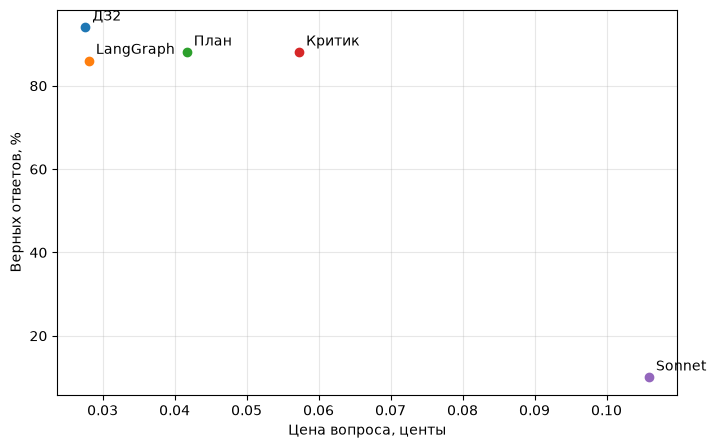

In [91]:
rows = [
    ("ДЗ2", 94, 0.0276),
    ("LangGraph", 86, 0.0281),
    ("План", 88, 0.0417),
    ("Критик", 88, 0.0573),
    ("Sonnet", 10, 0.1059),
]

fig, ax = plt.subplots(figsize=(8, 5))
for name, accuracy, cost in rows:
    ax.scatter(cost, accuracy)
    ax.annotate(name, (cost, accuracy), xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Цена вопроса, центы")
ax.set_ylabel("Верных ответов, %")
ax.grid(alpha=0.3)
(ROOT / "src" / "img").mkdir(exist_ok=True)
fig.savefig(ROOT / "src" / "img" / "money_all.png", bbox_inches="tight", dpi=150)
plt.show()

In [87]:
probe_rows = []

for tag, fn in [("проба цикла", bare_agent), ("проба графа", ask_langgraph)]:
    TAG["now"] = tag
    FIRST.pop(tag, None)
    before = len(CALLS)
    fn("What is 2 + 2? Reply with the number only.")
    calls = [
        c for c in CALLS[before:]
        if c["model"] == CHEAP.split("/")[-1]
    ]
    probe_rows.append({
        "вариант": tag,
        "токенов в первом запросе": calls[0]["prompt"],
    })

pd.DataFrame(probe_rows)

for tag in ["проба цикла", "проба графа"]:
    print(tag)
    print(json.dumps(FIRST[tag], ensure_ascii=False, indent=2))

проба цикла
{
  "model": "openai/gpt-4o-mini",
  "messages": [
    {
      "role": "system",
      "content": "You answer questions about events of 2026. Never answer from memory: look facts up with the tools, do not repeat the same call. When done, write the last line as FINAL: <short answer>, or NOT_FOUND if the knowledge base has no answer."
    },
    {
      "role": "user",
      "content": "What is 2 + 2? Reply with the number only."
    }
  ],
  "temperature": 0.0,
  "tools": [
    {
      "type": "function",
      "function": {
        "name": "knowledge_base",
        "description": "Searches the local knowledge base of 2026 events and returns the five closest facts with their page and section",
        "parameters": {
          "properties": {
            "query": {
              "description": "short search query in English: names, dates, key terms of the event",
              "title": "Query",
              "type": "string"
            },
            "page": {
             

In [90]:
task_by_id = {t["id"]: t for t in tasks}

for tag, rows in RESULTS.items():
    print("\nКОНФИГУРАЦИЯ:", tag)
    for r in [r for r in rows if not r["ok"]][:10]:
        task = task_by_id[r["id"]]
        print("\nВопрос:", task["question"])
        print("Эталон:", task["answer"])
        print("Ответ:", r["answer"])


КОНФИГУРАЦИЯ: LangGraph, mini

Вопрос: Who won the 2026 Spanish Grand Prix?
Эталон: Kimi Antonelli
Ответ: Lewis Hamilton won the 2026 Spanish Grand Prix, driving for Ferrari. The race took place on June 14, 2026. FINAL: Lewis Hamilton

Вопрос: Which song won Song of the Year at the 2026 Grammy Awards?
Эталон: WILDFLOWER
Ответ: Model call limits exceeded: run limit (7/7)

Вопрос: Who won Best Dance/Electronic Recording at the 2026 Grammy Awards?
Эталон: Tame Impala
Ответ: Model call limits exceeded: run limit (7/7)

Вопрос: Which album won Best Alternative Music Album at the 2026 Grammy Awards?
Эталон: Songs Of A Lost World
Ответ: Model call limits exceeded: run limit (7/7)

Вопрос: Which team won Super Bowl LX in 2026?
Эталон: Seattle Seahawks
Ответ: Model call limits exceeded: run limit (7/7)

Вопрос: What was the final score of Super Bowl LX in 2026?
Эталон: 29-13
Ответ: Model call limits exceeded: run limit (7/7)

Вопрос: Which country won the most medals overall at the 2026 Winter